**CAPSTONE PROJECT**

IMPACT OF SOCIAL MEDIA ON LIFE

Student Name            : Faseela Farsana PK

Course                  : Data Analytics

Institute               : Entri elevate

Project Submitted to    : Anuriya R



***INTRODUCTION***

My capstone project focuses on analyzing the impact of social media usage on students' mental health, sleep, and academic performance. This CSV file contains primary survey records of 4,500 students evaluating the relationship between daily social media exposure, sleep hygiene, perceived stress, and academic performance.

Key attributes include:

•	Demographics: Age, Gender, Academic Level (High School to Postgraduate).

•	Usage Metrics: Primary platform, average daily screen time, weekend excess hours, and primary access device.

•	Health & Psychometrics: Nightly sleep duration, subjective sleep quality score (1–5), late-night scrolling indicators, Perceived Stress Scale (PSS: 0–40), and composite Mental Health Index (10–98).

•	Academic & Outcome: Cumulative GPA and multi-factor classification label (Overall_Impact: Beneficial, Neutral, Negative).

**The main objective** is to explore patterns and relationships between social media behavior and students' well-being and academic performance. I will use Python for data cleaning, exploratory data analysis, visualization, and deriving meaningful insights from the dataset.


Original Dataset

https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life

Importing python libraries to perfom on the dataset which is need for the basic importing of datatset to finding the final visualisation of the datas.

In [ ]:
#importing the libraries panda, numpy, matplotlib and seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='Set2')

 **Data Loading and Initial Overview**

● Import the dataset using Pandas and provide an overview:

○ Number of rows and columns

○ Data types of each column

○ Initial observations - head, tail etc

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Capstonorg.csv to Capstonorg.csv


In [ ]:
df = pd.read_csv('Capstonorg.csv')

In [ ]:
#details of the columns
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [ ]:
#structure of the dataset
df.shape

(4514, 16)

In [ ]:
#Each column headings
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='object')

In [ ]:
#details of datas in each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4514 entries, 0 to 4513
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4514 non-null   object 
 1   Age                          4514 non-null   int64  
 2   Gender                       4508 non-null   object 
 3   Academic_Level               4514 non-null   object 
 4   Primary_Platform             4514 non-null   object 
 5   Daily_Usage_Hours            4514 non-null   float64
 6   Weekend_Extra_Hours          4514 non-null   float64
 7   Device_Type                  4486 non-null   object 
 8   Sleep_Duration_Hours         4514 non-null   float64
 9   Sleep_Quality_Score          4514 non-null   int64  
 10  Late_Night_Usage             4514 non-null   bool   
 11  Social_Comparison_Frequency  4514 non-null   object 
 12  Perceived_Stress_Score       4468 non-null   float64
 13  Mental_Health_Inde

 **TASK 2  - **Data Pre-processing** **

● Perform all necessary cleaning steps such as:

○ Handling missing values

○ Removing duplicates

○ Correcting data types

○ Creating derived columns

○ Filtering or aggregating data

In [ ]:
#calculating nullvalues
df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,6
Academic_Level,0
Primary_Platform,0
Daily_Usage_Hours,0
Weekend_Extra_Hours,0
Device_Type,28
Sleep_Duration_Hours,0
Sleep_Quality_Score,0


Found that 4 columns with some null values.

In [ ]:
print(df['Perceived_Stress_Score'].mean())
print(df['Perceived_Stress_Score'].median())
print(df['Academic_Performance_GPA'].mean())
print(df['Academic_Performance_GPA'].median())

13.516786034019695
13.0
3.4287669376693763
3.46


In [ ]:
#handling the missing values in neumerical column
df['Perceived_Stress_Score'] = df['Perceived_Stress_Score'].fillna(
    df['Perceived_Stress_Score'].median()
)

df['Academic_Performance_GPA'] = df['Academic_Performance_GPA'].fillna(
    df['Academic_Performance_GPA'].median()
)

In [ ]:
#handling the missing values in categorical column by using mode
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

df['Device_Type'] = df['Device_Type'].fillna(df['Device_Type'].mode()[0])

In [ ]:
#Corrected the columns having missing values
df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Academic_Level,0
Primary_Platform,0
Daily_Usage_Hours,0
Weekend_Extra_Hours,0
Device_Type,0
Sleep_Duration_Hours,0
Sleep_Quality_Score,0


All missing values were handled by using mode and median.

In [ ]:
#checking for duplicate values
df.duplicated().sum()

np.int64(15)

Found 15 duplicates..

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

Removed the duplicate rows.

In [ ]:
#Creating a new column named "usage category"
df['usage_category'] = pd.cut(
    df['Daily_Usage_Hours'],
    bins=[0, 2, 5, float('inf')],
    labels=['Low', 'Medium', 'High']
)

In [ ]:
df[['Daily_Usage_Hours', 'usage_category']].head()

,Daily_Usage_Hours,usage_category
0,7.5,High
1,4.6,Medium
2,10.9,High
3,6.0,High
4,3.3,Medium


In [ ]:
#creating a column named "sleep category"
df['sleep_category'] = pd.cut(
    df['Sleep_Duration_Hours'],
    bins=[0, 6, 8, float('inf')],
    labels=['Low Sleep', 'Normal Sleep', 'High Sleep']
)

Created two columns as 'usage category" and "Sleep category". It will help to bring analysis on social_media usage vs sleep, sleep vs stress score etc

TASK 3 - **EXPLORATORY DATA ANALYSIS**


**Monovariate analysis**.

In [ ]:
columns = [
    'Daily_Usage_Hours',
    'Sleep_Duration_Hours',
    'Perceived_Stress_Score',
    'Mental_Health_Index',
    'Academic_Performance_GPA'
]

df[columns].describe()

,Daily_Usage_Hours,Sleep_Duration_Hours,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4499.000000,4499.000000,4499.000000,4499.000000,4499.000000
mean,5.296710,6.701311,13.507668,79.869082,3.429796
std,2.604265,1.190129,7.037385,12.874638,0.388975
min,0.900000,3.000000,0.000000,32.000000,1.900000
25%,3.400000,6.000000,9.000000,72.000000,3.200000
50%,4.700000,6.800000,13.000000,82.000000,3.460000
75%,6.600000,7.500000,18.000000,89.000000,3.720000
max,14.000000,10.500000,40.000000,98.000000,4.000000


Descriptive statistics were used to understand the main characteristics of the dataset. The analysis included 4,499 observations for each of the five selected variables.

Participants spent an average of approximately 5.3 hours per day on social media and slept for an average of 6.7 hours. The mean perceived stress score was 13.51, while the mean mental health index was 79.87. The average academic performance GPA was 3.43.

Comparing the mean and median values suggests that daily usage and stress scores show some positive skewness, while mental health index and GPA show some negative skewness. These results help us understand the distribution of the data and prepare for further exploratory data analysis.

In [ ]:
df[columns].skew()

,0
Daily_Usage_Hours,1.135381
Sleep_Duration_Hours,-0.342833
Perceived_Stress_Score,0.587287
Mental_Health_Index,-0.810142
Academic_Performance_GPA,-0.643009


The skewness analysis was performed to understand the distribution of the data.

The results show that Daily Usage Hours and Perceived Stress Score are positively skewed. This means that their distributions have longer tails towards higher values.

Sleep Duration Hours, Mental Health Index, and Academic Performance GPA are negatively skewed, meaning their distributions have longer tails towards lower values.

In [ ]:
df['Daily_Usage_Hours'].value_counts().head(10)

,count
Daily_Usage_Hours,
3.8,107
4.9,97
4.0,94
3.1,90
4.4,90
3.2,89
3.9,89
4.3,89
4.5,89


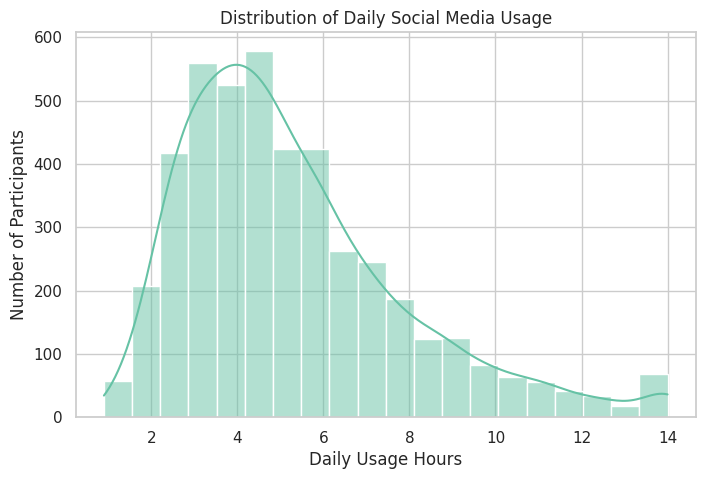

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Daily_Usage_Hours',
    bins=20,
    kde=True
)

plt.title('Distribution of Daily Social Media Usage')
plt.xlabel('Daily Usage Hours')
plt.ylabel('Number of Participants')

plt.show()

The histogram shows that daily social media usage is concentrated mainly between 3 and 5 hours. The distribution is positively skewed, with a long tail toward higher usage hours. This suggests that relatively fewer participants spend very long hours on social media.


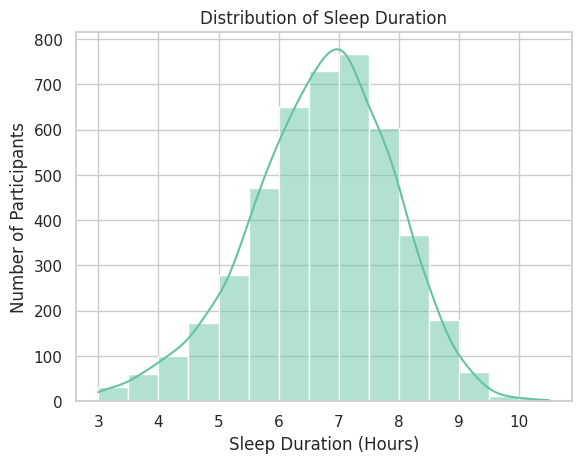

In [ ]:
sns.histplot(
    data=df,
    x='Sleep_Duration_Hours',
    bins=15,
    kde=True
)

plt.title('Distribution of Sleep Duration')
plt.xlabel('Sleep Duration (Hours)')
plt.ylabel('Number of Participants')
plt.show()

This histogram shows most people sleeping for acquarate time. for few of them social media usage affect with sleep.

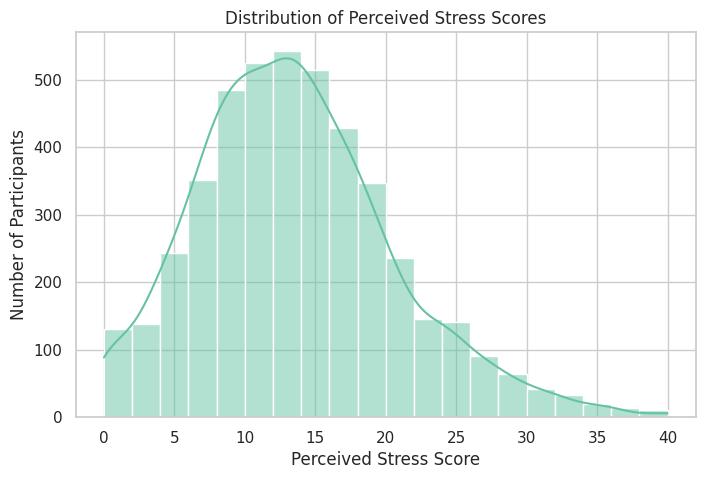

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Perceived_Stress_Score',
    bins=20,
    kde=True
)

plt.title('Distribution of Perceived Stress Scores')
plt.xlabel('Perceived Stress Score')
plt.ylabel('Number of Participants')

plt.show()

This univariate analysis also shows very few people having high stress score  as a part of socialmedia usage. More people having a stress score between 10-20.

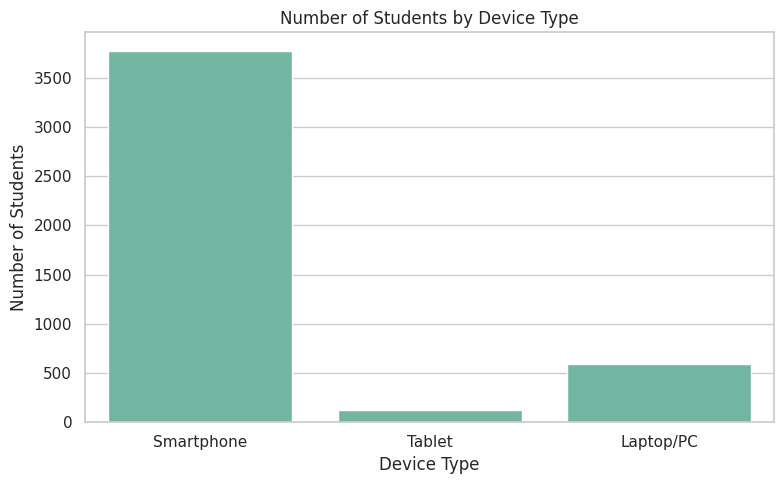

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Device_Type'
)

plt.title('Number of Students by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Number of Students')

plt.tight_layout()
plt.show()

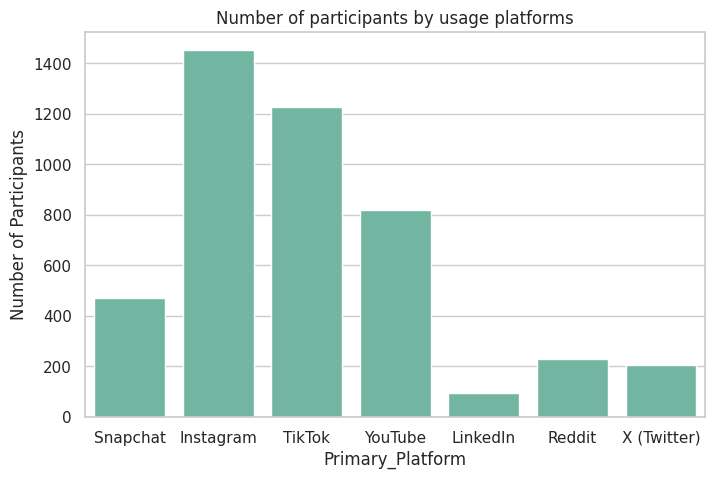

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x= 'Primary_Platform')

plt.title('Number of participants by usage platforms')
plt.xlabel('Primary_Platform')
plt.ylabel('Number of Participants')
plt.show()

Most of the students are using smartphone for social media usage, and instagram is the main platform used by most of them.  

In [ ]:
df.groupby('Overall_Impact').agg(
    Student_Count=('Daily_Usage_Hours', 'count'),
    Average_Usage=('Daily_Usage_Hours', 'mean'),
    Average_Sleep=('Sleep_Duration_Hours', 'mean'),
    Average_Stress=('Perceived_Stress_Score', 'mean'),
    Average_GPA=('Academic_Performance_GPA', 'mean')
).round(2)

,Student_Count,Average_Usage,Average_Sleep,Average_Stress,Average_GPA
Overall_Impact,,,,,
Beneficial,3680,4.42,7.03,11.18,3.54
Negative,165,12.25,4.23,31.01,2.56
Neutral,654,8.50,5.48,22.20,3.01


The analysis shows a clear difference in social media usage, sleep duration, perceived stress, and academic performance across the three impact groups.
- Beneficial impact: The majority of students (3,680) fall into this group. They have the lowest average social media usage (4.42 hours), the highest average sleep duration (7.03 hours), the lowest average stress score (11.18), and the highest average GPA (3.54).
- Negative impact: A smaller group of 165 students shows the highest average social media usage (12.25 hours), the lowest average sleep duration (4.23 hours), the highest average stress score (31.01), and the lowest average GPA (2.56).
- Neutral impact: The 654 students in this group show moderate usage (8.50 hours), sleep duration (5.48 hours), stress score (22.20), and GPA (3.01).

Overall, students in the beneficial impact group show more favorable patterns in sleep, stress, and academic performance, while those in the negative impact group show less favorable patterns. This suggests that excessive social media usage may be associated with reduced sleep, higher stress, and lower academic performance. However, these findings show associations, not proof that social media usage directly causes these outcomes.

In [ ]:
pivot_table = pd.pivot_table(
    df,
    index='Academic_Level',
    columns='Overall_Impact',
    values='Daily_Usage_Hours',
    aggfunc='mean'
).round(2)

pivot_table

Overall_Impact,Beneficial,Negative,Neutral
Academic_Level,,,
High School,4.44,12.58,8.44
Postgraduate,4.37,11.86,8.67
Undergraduate,4.41,12.10,8.52


cross all three academic levels, students in the negative impact group show substantially higher average social media usage than those in the beneficial impact group. High School students have the highest average usage in the negative group (12.58 hours), while Postgraduate students have the lowest (11.86 hours).

This suggests that the relationship between social media impact and usage duration is consistent across academic levels.

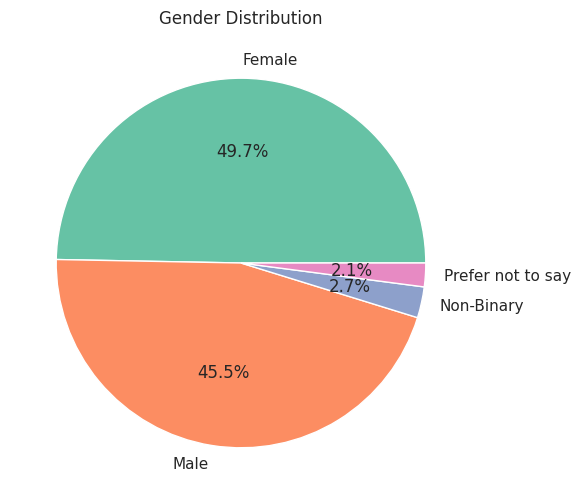

In [ ]:
df['Gender'].value_counts().plot.pie(
    autopct='%1.1f%%',
    figsize=(6, 6)
)

plt.title('Gender Distribution')
plt.ylabel('')
plt.show()

**BIVARIATE ANALYSIS**

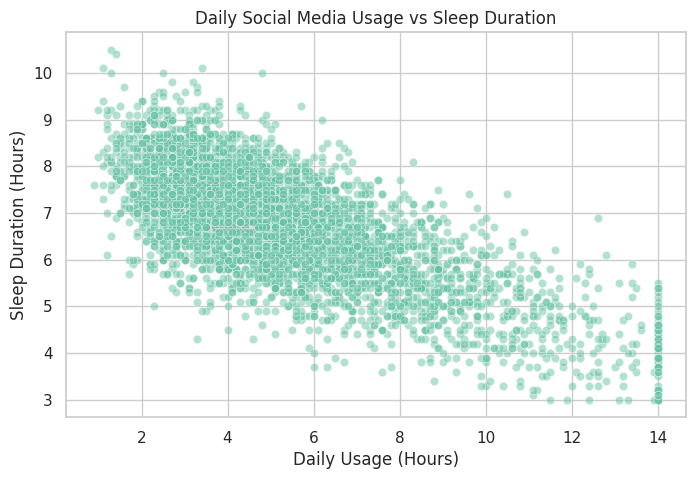

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Daily_Usage_Hours',
    y='Sleep_Duration_Hours',
    alpha=0.5
)

plt.title('Daily Social Media Usage vs Sleep Duration')
plt.xlabel('Daily Usage (Hours)')
plt.ylabel('Sleep Duration (Hours)')

plt.show()

In [ ]:
df['Daily_Usage_Hours'].corr(
    df['Sleep_Duration_Hours']
)

np.float64(-0.7160218228673964)

Correlation between Social media usage and sleep

The correlation analysis showed a strong negative relationship between daily social media usage and sleep duration (r = −0.716). This suggests that participants who spend more time on social media tend to sleep for fewer hours. However, correlation does not prove that increased social media usage causes reduced sleep duration.

In [ ]:
df['Daily_Usage_Hours'].corr(
    df['Perceived_Stress_Score']
)

np.float64(0.7507031013525026)

Correlation between Social Media Usage and Stress

The correlation analysis showed a strong positive relationship between daily social media usage and perceived stress scores (r = 0.751). This suggests that participants who spend more time on social media tend to report higher stress scores. However, this relationship does not prove that social media usage directly causes stress.

In [ ]:
df['Daily_Usage_Hours'].corr(
    df['Academic_Performance_GPA']
)

np.float64(-0.704334700440339)

Correlation between Social Media Usage and Academic Performance

The correlation analysis showed a strong negative relationship between daily social media usage and academic performance GPA (r = −0.704). This suggests that participants who spend more time on social media tend to have lower GPAs. However, this relationship does not prove that social media usage directly causes lower academic performance.

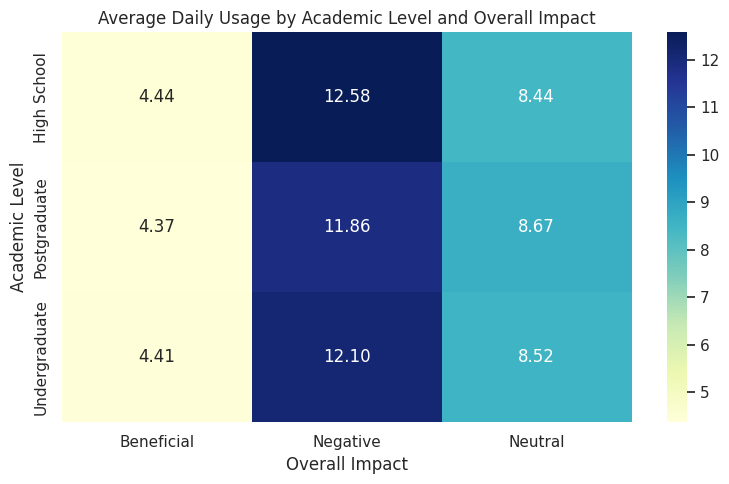

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    pivot_table,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Average Daily Usage by Academic Level and Overall Impact')
plt.xlabel('Overall Impact')
plt.ylabel('Academic Level')

plt.tight_layout()
plt.show()

Higher daily usage (approx. 12 hours) strongly aligns with negative outcomes, whereas controlled, moderate usage (approx. 4.4 hours) is consistently associated with beneficial impacts across all student demographics.

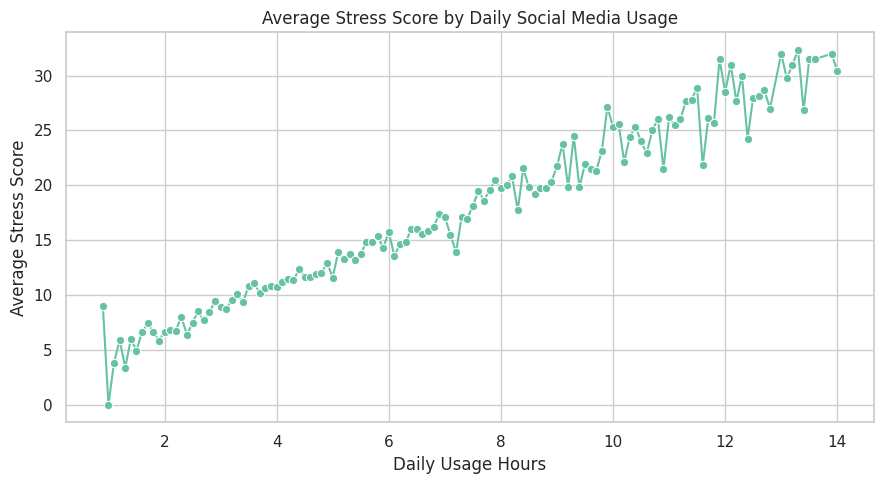

In [ ]:
stress_trend = (
    df.groupby('Daily_Usage_Hours')['Perceived_Stress_Score']
    .mean()
    .reset_index()
    .sort_values('Daily_Usage_Hours')
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=stress_trend,
    x='Daily_Usage_Hours',
    y='Perceived_Stress_Score',
    marker='o'
)

plt.title('Average Stress Score by Daily Social Media Usage')
plt.xlabel('Daily Usage Hours')
plt.ylabel('Average Stress Score')
plt.tight_layout()
plt.show()

The line chart show a trend of increasing stress score among students who uses social media for a long duration.

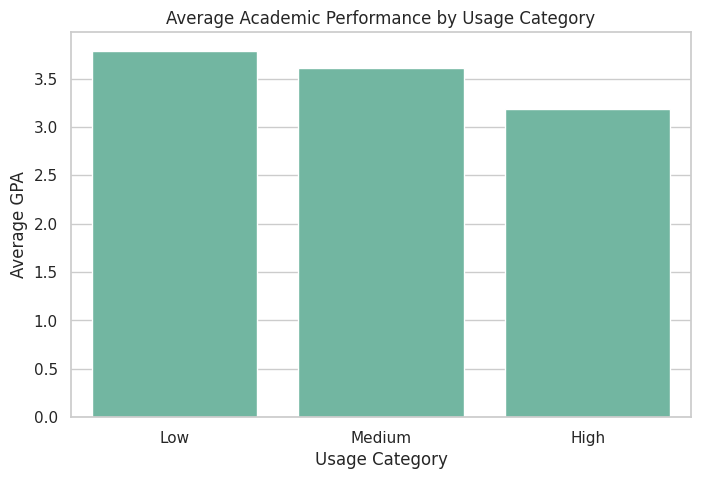

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='usage_category',
    y='Academic_Performance_GPA',
    errorbar=None
)

plt.title('Average Academic Performance by Usage Category')
plt.xlabel('Usage Category')
plt.ylabel('Average GPA')
plt.show()

This barplot shows students with high usage of socila media tends to show a lower academic perfomance.

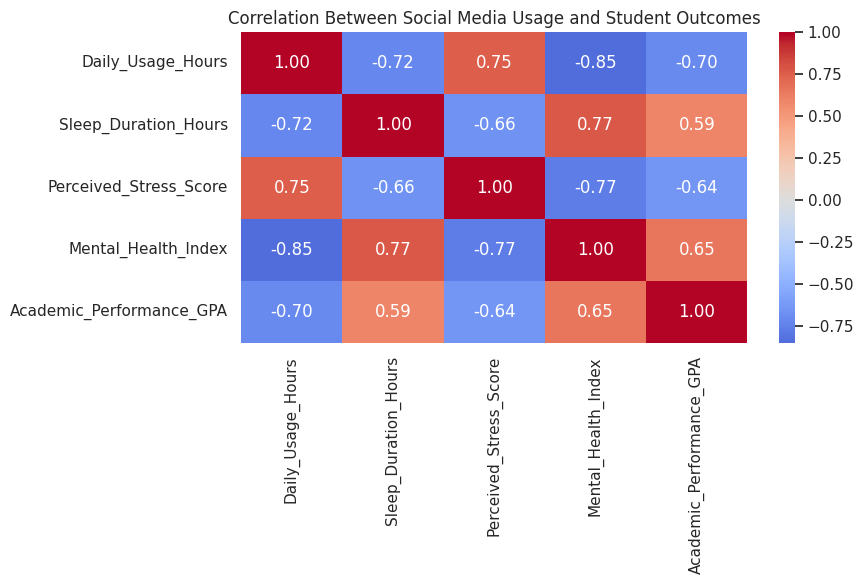

In [ ]:
columns = [
    'Daily_Usage_Hours',
    'Sleep_Duration_Hours',
    'Perceived_Stress_Score',
    'Mental_Health_Index',
    'Academic_Performance_GPA'
]

correlation_matrix = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Between Social Media Usage and Student Outcomes')
plt.tight_layout()
plt.show()

This heatmap shows the relationship between social media usage, sleep duration, perceived stress, mental health, and academic performance (GPA) among students.

Daily usage and mental health

Daily social media usage has a strong negative correlation with the Mental Health Index (-0.85). As daily usage increases, the index tends to decrease. The interpretation depends on whether a higher index represents better or poorer mental health.

Daily usage and stress

Daily usage has a strong positive correlation with perceived stress (0.75). Students with higher daily usage tend to have higher stress scores.

Daily usage and sleep

Daily usage is strongly negatively correlated with sleep duration (-0.72). Higher usage tends to be associated with fewer hours of sleep.
Daily usage and academic performance

Daily usage has a strong negative correlation with GPA (-0.70). Higher social media usage tends to be associated with lower academic performance.

Sleep and mental health

Sleep duration has a strong positive correlation with the Mental Health Index (0.77). Students who sleep longer tend to have higher index values.

Stress and mental health

Perceived stress has a strong negative correlation with the Mental Health Index (-0.77). Higher stress tends to be associated with a lower index.
Sleep duration and GPA have a positive correlation of +0.59, suggesting that longer sleep is associated with better academic performance.



Stress and GPA have a negative correlation of -0.64, suggesting that higher stress is associated with lower GPA.



Mental Health Index and GPA have a positive correlation of +0.65, suggesting that higher index values are associated with better academic performance if higher scores indicate better mental health.

Impact of Social Media Usage on Student Outcomes

The correlation analysis reveals notable relationships between daily social media usage, sleep duration, perceived stress, mental health, and academic performance. Daily social media usage shows a strong negative correlation with sleep duration (-0.72), Mental Health Index (-0.85), and academic performance (-0.70), while showing a strong positive correlation with perceived stress (+0.75). Sleep duration is positively correlated with mental health (+0.77) and academic performance (+0.59). These findings suggest that higher social media usage is associated with less sleep, higher stress, and lower academic performance.

In [ ]:
df.groupby('Late_Night_Usage')['Mental_Health_Index'].mean()

,Mental_Health_Index
Late_Night_Usage,
False,84.477371
True,76.632993


In [ ]:
df.groupby('Late_Night_Usage')['Academic_Performance_GPA'].mean()

,Academic_Performance_GPA
Late_Night_Usage,
False,3.546681
True,3.347715


In [ ]:
df.groupby('Late_Night_Usage')['Perceived_Stress_Score'].mean()

,Perceived_Stress_Score
Late_Night_Usage,
False,11.177802
True,15.143776


In [ ]:
df.groupby('Late_Night_Usage')[
    ['Mental_Health_Index',
     'Academic_Performance_GPA',
     'Perceived_Stress_Score']
].mean()

,Mental_Health_Index,Academic_Performance_GPA,Perceived_Stress_Score
Late_Night_Usage,,,
False,84.477371,3.546681,11.177802
True,76.632993,3.347715,15.143776


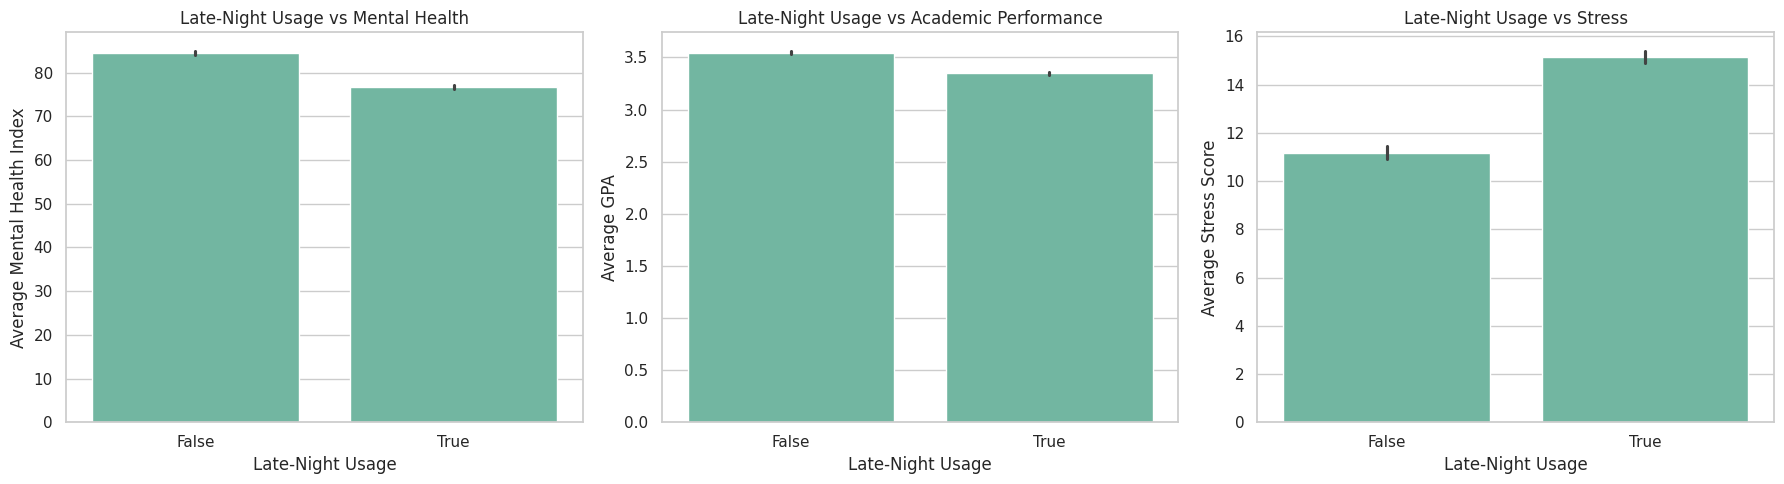

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Mental Health
sns.barplot(data=df, x='Late_Night_Usage',
            y='Mental_Health_Index', ax=axes[0])
axes[0].set_title('Late-Night Usage vs Mental Health')
axes[0].set_xlabel('Late-Night Usage')
axes[0].set_ylabel('Average Mental Health Index')

# Chart 2: Academic Performance
sns.barplot(data=df, x='Late_Night_Usage',
            y='Academic_Performance_GPA', ax=axes[1])
axes[1].set_title('Late-Night Usage vs Academic Performance')
axes[1].set_xlabel('Late-Night Usage')
axes[1].set_ylabel('Average GPA')

# Chart 3: Perceived Stress
sns.barplot(data=df, x='Late_Night_Usage',
            y='Perceived_Stress_Score', ax=axes[2])
axes[2].set_title('Late-Night Usage vs Stress')
axes[2].set_xlabel('Late-Night Usage')
axes[2].set_ylabel('Average Stress Score')

plt.tight_layout()
plt.show()

Mental Health Index: Students who do not use phones late at night (False) have a higher average index (around 84) than students who do (True, around 76).



Academic Performance (GPA): The average GPA appears almost similar for both groups, around 3.2–3.4.



Perceived Stress Score: Students who use phones late at night have a higher average stress score (around 15) than those who do not (around 11).





1. Mental health: Late-night phone users have a lower average Mental Health Index, suggesting a possible association between late-night usage and poorer mental well-being.
2. Academic performance: The average GPA is relatively similar in both groups. In this chart, there is no clear difference in academic performance based on late-night phone usage.
3. Stress: Late-night phone users have a higher average perceived stress score, suggesting that late-night usage may be associated with increased stress.

The analysis indicates that students who use their phones late at night have a lower average Mental Health Index and a higher Perceived Stress Score compared with students who do not. However, academic performance appears relatively similar between the two groups. These findings suggest a possible association between late-night phone usage, mental well-being, and stress levels.

***CONCLUSION***

---


The exploratory data analysis of the "Impact of Social Media on Life" dataset identified meaningful relationships between social media usage, sleep duration, perceived stress, mental health, and academic performance.

Daily social media usage showed a strong negative correlation with the Mental Health Index (−0.85) and academic GPA (−0.70), and a positive correlation with perceived stress (+0.75). It was also negatively correlated with sleep duration (−0.72). These findings indicate that higher social media usage was associated with less favourable sleep, stress, mental health, and academic indicators in this dataset.

The comparison of late-night users and non-late-night users further showed that late-night users had a lower average Mental Health Index and higher average perceived stress scores, while their academic GPA was relatively similar.Overall, the analysis highlights the importance of balanced social media usage, healthy sleep routines, stress management, and effective study habits.


***Recommendations***

1. Encourage healthy screen-time habits

Students should monitor their daily social media usage and set reasonable screen-time limits, particularly when usage becomes excessive or interferes with their daily routines.

2. Reduce social media use before bedtime

Encourage students to establish a consistent sleep schedule and limit late-night scrolling to help protect their sleep routines.

3. Promote mental well-being and stress management

Educational institutions can provide stress-management activities, counselling resources, and awareness programmes about balanced social media use.

4. Support healthy study habits

Students can schedule dedicated study periods, take planned breaks, and reduce unnecessary notifications during study time.
